# MyTorch: Multi-class benchmark on FEN positions

This notebook uses the project's FEN parser to load positions from `../dataset`, then compares three neural-network configurations on the same reproducible train/validation split:

| Model | Hidden layers | Initial weight range | Learning rate |
|---|---:|---:|---:|
| Baseline | 24 | ±0.08 | 0.05 |
| Wider | 48 | ±0.04 | 0.02 |
| Deeper | 32, 16 | ±0.04 | 0.02 |

It plots train/validation loss and accuracy for each model, final metric comparisons, validation confusion matrices, and per-class precision/recall. The benchmark compares configurations, not a fully validated implementation of backpropagation; interpret the results accordingly.


In [55]:
from collections import defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from my_torch import (
    LayerSettings,
    NNSettings,
    NeuralNetwork,
    sigmoid,
    sigmoid_derivative,
)
from my_torch.typing import DataPair
from parsing import FENParseError, FENParser

SEED = 42
rng = np.random.default_rng(SEED)
fen_parser = FENParser()
class_names = ["Nothing", "Check White", "Check Black", "Checkmate White", "Checkmate Black"]
MAX_PER_CLASS = 400

dataset_dir = Path("../dataset").resolve()
dataset_files = sorted(dataset_dir.rglob("*.txt"))
if not dataset_files:
    raise FileNotFoundError(f"No dataset text files found under {dataset_dir}")

reservoirs = defaultdict(list)
seen_per_class = defaultdict(int)
for dataset_file in dataset_files:
    with dataset_file.open(encoding="utf-8") as source:
        for line_number, line in enumerate(source, start=1):
            if not line.strip():
                continue
            try:
                record = fen_parser.parse_line(line)
            except FENParseError as error:
                raise ValueError(f"{dataset_file}:{line_number}: {error}") from error

            label = record.expected_result
            if label not in class_names:
                raise ValueError(f"Unknown class {label!r} at {dataset_file}:{line_number}")
            seen_per_class[label] += 1
            reservoir = reservoirs[label]
            if len(reservoir) < MAX_PER_CLASS:
                reservoir.append(record.position)
            else:
                replacement = rng.integers(seen_per_class[label])
                if replacement < MAX_PER_CLASS:
                    reservoir[replacement] = record.position

missing_classes = [name for name in class_names if not reservoirs[name]]
if missing_classes:
    raise ValueError(f"Dataset has no examples for classes: {missing_classes}")

piece_order = "PNBRQKpnbrqk"

def encode_position(position):
    encoded = np.zeros(64 * len(piece_order) + 2, dtype=np.float64)
    square = 0
    for rank in position.board:
        for piece in rank:
            if piece is not None:
                encoded[square * len(piece_order) + piece_order.index(piece)] = 1.0
            square += 1
    if square != 64:
        raise ValueError("Parsed position does not contain 64 squares")
    encoded[64 * len(piece_order) + (0 if position.active_color == "w" else 1)] = 1.0
    return encoded

features_list, labels_list = [], []
for class_id, class_name in enumerate(class_names):
    for position in reservoirs[class_name]:
        features_list.append(encode_position(position))
        labels_list.append(class_id)

features = np.vstack(features_list)
labels = np.asarray(labels_list, dtype=int)

train_indices, validation_indices = [], []
for class_id in range(len(class_names)):
    class_indices = rng.permutation(np.flatnonzero(labels == class_id))
    split_at = int(0.8 * len(class_indices))
    train_indices.extend(class_indices[:split_at])
    validation_indices.extend(class_indices[split_at:])
train_indices = rng.permutation(train_indices)
validation_indices = rng.permutation(validation_indices)
one_hot = np.eye(len(class_names))[labels]

train_data = [
    DataPair(features[index].reshape(1, -1), one_hot[index].reshape(1, -1))
    for index in train_indices
]
X_train, y_train = features[train_indices], labels[train_indices]
X_validation, y_validation = features[validation_indices], labels[validation_indices]

print(f"Dataset: {dataset_dir}")
print(f"Files used: {len(dataset_files)} | examples: {len(labels)}")
print(f"Train: {len(train_data)} | validation: {len(y_validation)} | features: {features.shape[1]}")


Dataset: /home/armand/tek3/G-CNA-501-PAR-5-1-mytorch-1/my_torch/dataset
Files used: 9 | examples: 2000
Train: 1600 | validation: 400 | features: 770


In [56]:
model_configs = [
    {
        "name": "Baseline: 1 x 24",
        "hidden_sizes": [24],
        "weight_scale": 0.08,
        "learning_rate": 0.05,
    },
    {
        "name": "Wider: 1 x 48",
        "hidden_sizes": [48],
        "weight_scale": 0.04,
        "learning_rate": 0.02,
    },
    {
        "name": "Deeper: 32 + 16",
        "hidden_sizes": [32, 16],
        "weight_scale": 0.04,
        "learning_rate": 0.02,
    },
]
EPOCHS = 15


def predict_probabilities(network, X):
    return np.vstack([network.forward(row.reshape(1, -1))[0] for row in X])


def evaluate(network, X, targets):
    probabilities = predict_probabilities(network, X)
    expected = np.eye(len(class_names))[targets]
    loss = float(np.mean((probabilities - expected) ** 2))
    accuracy = float(np.mean(np.argmax(probabilities, axis=1) == targets))
    return loss, accuracy, probabilities


benchmark_results = {}
for model_index, config in enumerate(model_configs):
    model_rng = np.random.default_rng(SEED + model_index + 1)

    def uniform_weight(scale=config["weight_scale"], rng_for_model=model_rng):
        return float(rng_for_model.uniform(-scale, scale))

    def zero_bias():
        return 0.0

    hidden_layers = [
        LayerSettings(
            neurons=hidden_size,
            default_weight=uniform_weight,
            default_bias=zero_bias,
            activation_function=relu,
            derivative_activation=relu_derivative,
        )
        for hidden_size in config["hidden_sizes"]
    ]
    output_layer = LayerSettings(
        neurons=len(class_names),
        default_weight=uniform_weight,
        default_bias=zero_bias,
        activation_function=relu,
        derivative_activation=relu_derivative,
    )
    network = NeuralNetwork(
        NNSettings(
            input_count=features.shape[1],
            hidden_layers=hidden_layers,
            output_layer=output_layer,
        )
    )

    histories = {
        "train_loss": [],
        "validation_loss": [],
        "train_accuracy": [],
        "validation_accuracy": [],
    }
    for epoch in range(EPOCHS):
        for index in model_rng.permutation(train_indices):
            network.back_propagation(
                features[index].reshape(1, -1),
                one_hot[index].reshape(1, -1),
                learning_rate=config["learning_rate"],
            )

        train_loss, train_accuracy, _ = evaluate(network, X_train, y_train)
        validation_loss, validation_accuracy, _ = evaluate(
            network, X_validation, y_validation
        )
        histories["train_loss"].append(train_loss)
        histories["validation_loss"].append(validation_loss)
        histories["train_accuracy"].append(train_accuracy)
        histories["validation_accuracy"].append(validation_accuracy)

    _, _, validation_probabilities = evaluate(network, X_validation, y_validation)
    benchmark_results[config["name"]] = {
        "config": config,
        "network": network,
        "histories": histories,
        "validation_probabilities": validation_probabilities,
    }
    print(
        f"{config['name']}: train accuracy {train_accuracy:.1%} | "
        f"validation accuracy {validation_accuracy:.1%}"
    )


Baseline: 1 x 24: train accuracy 90.2% | validation accuracy 48.5%
Wider: 1 x 48: train accuracy 78.0% | validation accuracy 49.0%
Deeper: 32 + 16: train accuracy 20.0% | validation accuracy 20.0%


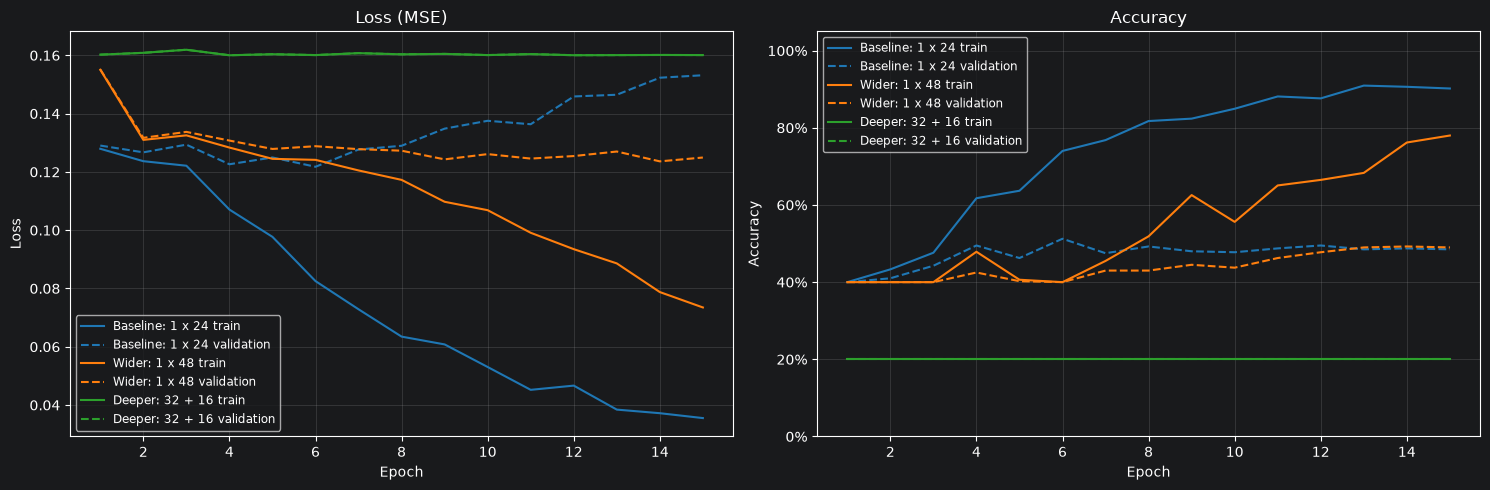

Final metric comparison
Model                   Train loss   Val. loss  Train acc.  Val. acc.
Baseline: 1 x 24            0.0355      0.1532      90.2%     48.5%
Wider: 1 x 48               0.0735      0.1249      78.0%     49.0%
Deeper: 32 + 16             0.1601      0.1601      20.0%     20.0%


In [57]:
epochs = np.arange(1, EPOCHS + 1)
colors = plt.cm.tab10(np.arange(len(model_configs)))
fig, (loss_axis, accuracy_axis) = plt.subplots(1, 2, figsize=(15, 5))

for color, config in zip(colors, model_configs):
    histories = benchmark_results[config["name"]]["histories"]
    loss_axis.plot(
        epochs, histories["train_loss"], color=color, linestyle="-",
        label=f"{config['name']} train",
    )
    loss_axis.plot(
        epochs, histories["validation_loss"], color=color, linestyle="--",
        label=f"{config['name']} validation",
    )
    accuracy_axis.plot(
        epochs, histories["train_accuracy"], color=color, linestyle="-",
        label=f"{config['name']} train",
    )
    accuracy_axis.plot(
        epochs, histories["validation_accuracy"], color=color, linestyle="--",
        label=f"{config['name']} validation",
    )

loss_axis.set(title="Loss (MSE)", xlabel="Epoch", ylabel="Loss")
loss_axis.grid(alpha=0.25)
loss_axis.legend(fontsize="small")
accuracy_axis.set(title="Accuracy", xlabel="Epoch", ylabel="Accuracy", ylim=(0, 1.05))
accuracy_axis.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f"{value:.0%}"))
accuracy_axis.grid(alpha=0.25)
accuracy_axis.legend(fontsize="small")
fig.tight_layout()
plt.show()

print("Final metric comparison")
print(f"{'Model':<22} {'Train loss':>11} {'Val. loss':>11} {'Train acc.':>11} {'Val. acc.':>10}")
for config in model_configs:
    histories = benchmark_results[config["name"]]["histories"]
    print(
        f"{config['name']:<22} "
        f"{histories['train_loss'][-1]:>11.4f} "
        f"{histories['validation_loss'][-1]:>11.4f} "
        f"{histories['train_accuracy'][-1]:>10.1%} "
        f"{histories['validation_accuracy'][-1]:>9.1%}"
    )


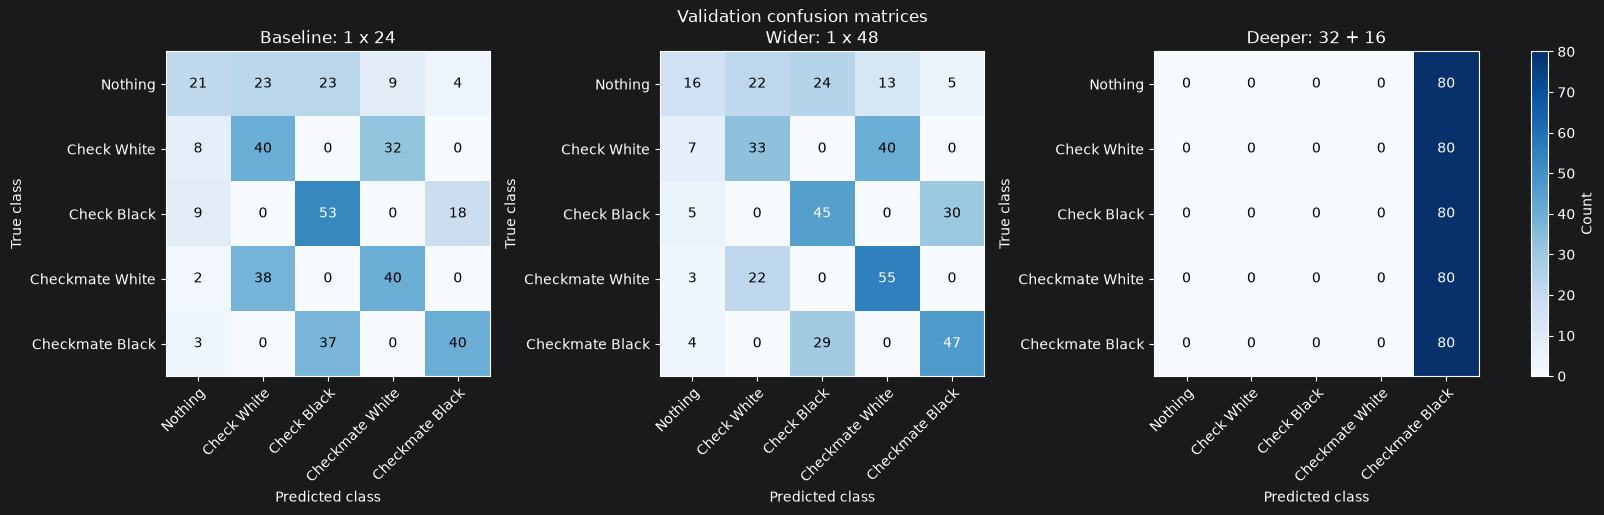

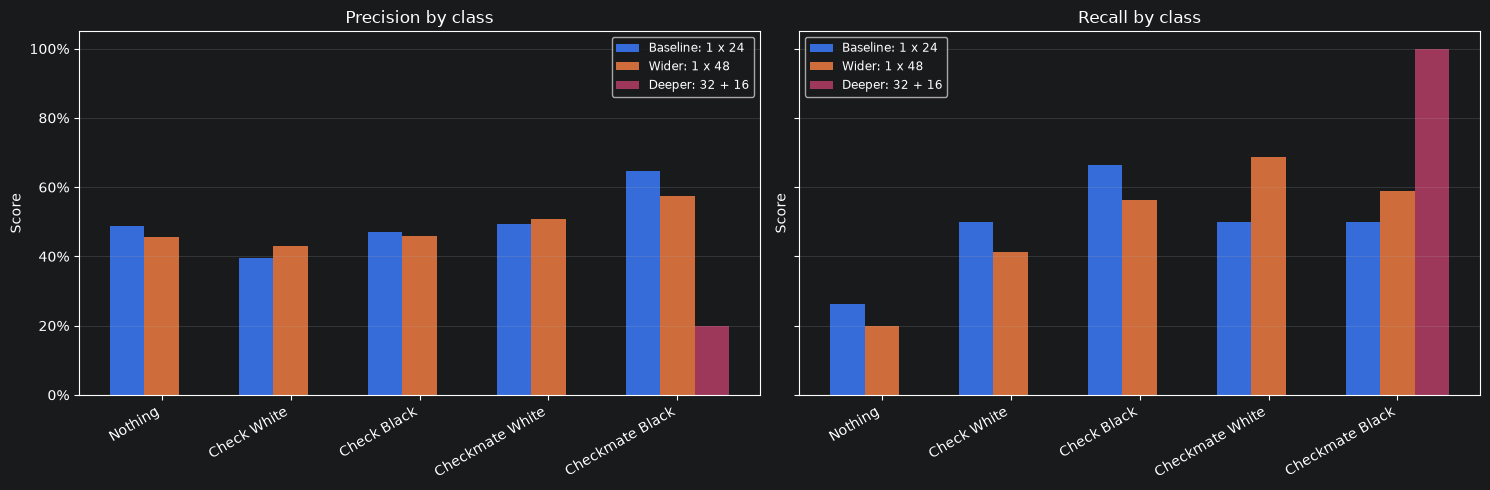

In [58]:
for config in model_configs:
    model_name = config["name"]
    validation_probabilities = benchmark_results[model_name]["validation_probabilities"]
    y_predicted = np.argmax(validation_probabilities, axis=1)

    confusion = np.zeros((len(class_names), len(class_names)), dtype=int)
    np.add.at(confusion, (y_validation, y_predicted), 1)
    true_positives = np.diag(confusion)
    precision = np.divide(
        true_positives,
        confusion.sum(axis=0),
        out=np.zeros(len(class_names), dtype=float),
        where=confusion.sum(axis=0) != 0,
    )
    recall = np.divide(
        true_positives,
        confusion.sum(axis=1),
        out=np.zeros(len(class_names), dtype=float),
        where=confusion.sum(axis=1) != 0,
    )
    benchmark_results[model_name]["confusion"] = confusion
    benchmark_results[model_name]["precision"] = precision
    benchmark_results[model_name]["recall"] = recall

fig, axes = plt.subplots(1, len(model_configs), figsize=(16, 5), layout="constrained")
maximum_count = max(result["confusion"].max() for result in benchmark_results.values())
for axis, config in zip(axes, model_configs):
    confusion = benchmark_results[config["name"]]["confusion"]
    image = axis.imshow(confusion, cmap="Blues", vmin=0, vmax=maximum_count)
    axis.set(
        title=config["name"],
        xlabel="Predicted class",
        ylabel="True class",
        xticks=np.arange(len(class_names)),
        yticks=np.arange(len(class_names)),
        xticklabels=class_names,
        yticklabels=class_names,
    )
    plt.setp(axis.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")
    threshold = maximum_count / 2
    for row in range(len(class_names)):
        for column in range(len(class_names)):
            axis.text(
                column, row, str(confusion[row, column]),
                ha="center", va="center",
                color="white" if confusion[row, column] > threshold else "black",
            )
fig.colorbar(image, ax=axes, fraction=0.025, pad=0.04, label="Count")
fig.suptitle("Validation confusion matrices")
plt.show()

positions = np.arange(len(class_names))
bar_width = 0.8 / len(model_configs)
fig, (precision_axis, recall_axis) = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
for model_index, config in enumerate(model_configs):
    offset = (model_index - (len(model_configs) - 1) / 2) * bar_width
    result = benchmark_results[config["name"]]
    precision_axis.bar(positions + offset, result["precision"], bar_width, label=config["name"])
    recall_axis.bar(positions + offset, result["recall"], bar_width, label=config["name"])

for axis, title in ((precision_axis, "Precision by class"), (recall_axis, "Recall by class")):
    axis.set(
        title=title,
        ylabel="Score",
        ylim=(0, 1.05),
        xticks=positions,
        xticklabels=class_names,
    )
    axis.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f"{value:.0%}"))
    axis.grid(axis="y", alpha=0.25)
    axis.legend(fontsize="small")
    plt.setp(axis.get_xticklabels(), rotation=30, ha="right")
fig.tight_layout()
plt.show()
